# Week 3: Which factors change turnover?

**Purpose.** This notebook builds the evidence base for `FINDINGS.md`. For each product group it measures how much turnover changes with **weekday, season, holidays, weather and Kiel Week**. It also re-checks the Week 1 (seasonal bread) and Week 2 (weekday) patterns, so all numbers in `FINDINGS.md` come from code in this repository.

**Important limits (read before the results):**
- Turnover is a money amount without currency and is **not** a number of pieces. Effects are shown in **%**.
- The weather is the weather that was **observed** on the day. At decision time (about 14:00 the day before) only a **forecast** is known, so real forecasts will work less well than these numbers suggest.
- Kiel Week and the holidays occur only **5 times** in the data, so those effects rest on few cases.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
GROUPS = {1: "Bread", 2: "Rolls", 3: "Croissants", 4: "Confectionery", 5: "Cakes", 6: "Seasonal bread"}
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]  # Monday to Sunday, never alphabetical
pd.set_option("display.precision", 1)

## 1. Load the three files and merge them on the date

A **merge** (join) adds the weather and Kiel Week columns to every sales row with the same date. We use a *left* join: every sales row is kept, even if no weather exists for that day. **Check:** the number of rows must be the same before and after the merge; otherwise a date appeared twice and rows were duplicated.

In [2]:
sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
weather = pd.read_csv(BASE_URL + "wetter.csv", parse_dates=["Datum"])
kiwo = pd.read_csv(BASE_URL + "kiwo.csv", parse_dates=["Datum"])

rows_before = len(sales)
df = sales.merge(weather, on="Datum", how="left").merge(kiwo, on="Datum", how="left")
df["KielerWoche"] = df["KielerWoche"].fillna(0).astype(int)  # days not in kiwo.csv are not Kiel Week

assert len(df) == rows_before, "merge changed the number of rows"
print(f"Rows before merge: {rows_before}, after merge: {len(df)}")
print("Sales rows without temperature:", df["Temperatur"].isna().sum(), "| without cloud cover:", df["Bewoelkung"].isna().sum())
print("Kiel Week days with sales:", df.loc[df.KielerWoche == 1, "Datum"].nunique())

df["group"] = df["Warengruppe"].map(GROUPS)
df["weekday"] = pd.Categorical(df["Datum"].dt.day_name(), categories=WEEKDAYS, ordered=True)
df["month"] = df["Datum"].dt.month
df["year"] = df["Datum"].dt.year

Rows before merge: 9334, after merge: 9334
Sales rows without temperature: 16 | without cloud cover: 70
Kiel Week days with sales: 45


## 2. Re-check Week 1: the seasonal bread season

Seasonal bread (group 6) is only sold from October to January. We look at its average daily turnover per half-month, and test whether **November** turnover differs from **October** (Welch t-test: compares two averages without assuming equal spread). Days within a season are not independent, so the real number of independent cases is the number of **seasons**, not days.

In [3]:
sb = df[df.Warengruppe == 6].copy()
sb["season"] = np.where(sb.month >= 10, sb.year.astype(str) + "/" + (sb.year + 1).astype(str).str[-2:],
                        (sb.year - 1).astype(str) + "/" + sb.year.astype(str).str[-2:])
sb["half_month"] = sb.Datum.dt.strftime("%m") + np.where(sb.Datum.dt.day <= 15, "-a (1-15)", "-b (16-end)")
order = ["10-a (1-15)", "10-b (16-end)", "11-a (1-15)", "11-b (16-end)", "12-a (1-15)", "12-b (16-end)", "01-a (1-15)", "01-b (16-end)"]
print("Days and date range per season:")
print(sb.groupby("season").Datum.agg(["count", "min", "max"]))
half = sb.groupby("half_month").Umsatz.agg(["count", "mean"]).reindex(order)
print("\nAverage daily turnover per half-month (all seasons):"); print(half)

Days and date range per season:
         count        min        max
season                              
2013/14     65 2013-10-24 2014-01-02
2014/15     66 2014-10-24 2015-01-06
2015/16     53 2015-11-02 2015-12-31
2016/17     52 2016-11-03 2016-12-29
2017/18     56 2017-10-30 2017-12-27

Average daily turnover per half-month (all seasons):
               count  mean
half_month                
10-a (1-15)      NaN   NaN
10-b (16-end)   13.0  34.6
11-a (1-15)     68.0  43.6
11-b (16-end)   72.0  73.2
12-a (1-15)     75.0  89.5
12-b (16-end)   58.0  68.2
01-a (1-15)      6.0  30.8
01-b (16-end)    NaN   NaN


In [4]:
# Late November jump: average of 16-30 Nov vs 1-15 Nov, per season
nov = sb[sb.month == 11].assign(part=lambda d: np.where(d.Datum.dt.day <= 15, "1-15 Nov", "16-30 Nov"))
nov_tab = nov.pivot_table(index="season", columns="part", values="Umsatz", aggfunc="mean")
nov_tab["change %"] = (nov_tab["16-30 Nov"] / nov_tab["1-15 Nov"] - 1) * 100
print(nov_tab)

oct_ = sb[sb.month == 10].Umsatz; nov_ = sb[sb.month == 11].Umsatz
t = stats.ttest_ind(nov_, oct_, equal_var=False)
print(f"\nOctober: {len(oct_)} days, mean {oct_.mean():.1f} | November: {len(nov_)} days, mean {nov_.mean():.1f}")
print(f"November vs October: {(nov_.mean()/oct_.mean()-1)*100:+.0f} %, Welch t = {t.statistic:.1f}, p = {t.pvalue:.2g}")
per_season = sb[sb.month.isin([10, 11])].pivot_table(index="season", columns="month", values="Umsatz", aggfunc="mean")
per_season["Nov vs Oct %"] = (per_season[11] / per_season[10] - 1) * 100
print("\nPer season:"); print(per_season)

part     1-15 Nov  16-30 Nov  change %
season                                
2013/14      48.8       81.1      66.1
2014/15      48.0       60.5      26.1
2015/16      37.9       82.1     116.4
2016/17      43.1       81.2      88.5
2017/18      38.8       61.5      58.6

October: 13 days, mean 34.6 | November: 140 days, mean 58.8
November vs October: +70 %, Welch t = 5.2, p = 2.6e-05

Per season:
month      10    11  Nov vs Oct %
season                           
2013/14  28.7  64.9         126.6
2014/15  36.9  54.0          46.4
2015/16   NaN  61.8           NaN
2016/17   NaN  64.2           NaN
2017/18  64.6  50.1         -22.4


## 3. Re-check Week 2: weekday patterns per product group

For each product group: average turnover per weekday, and the change in % against the **Monday-Friday average**. To see how **consistent** the pattern is, we compare Saturday and Sunday with the Monday-Friday average **of the same week**, and count in how many weeks the weekend day is higher.

In [5]:
wd = df.pivot_table(index="group", columns="weekday", values="Umsatz", aggfunc="mean", observed=False).reindex(list(GROUPS.values()))
monfri = wd[WEEKDAYS[:5]].mean(axis=1)
wd_pct = wd.div(monfri, axis=0).sub(1).mul(100)
print("Average daily turnover per weekday:"); print(wd.round(0))
print("\nChange vs Monday-Friday average (%):"); print(wd_pct.round(0))

Average daily turnover per weekday:
weekday         Monday  Tuesday  Wednesday  Thursday  Friday  Saturday  Sunday
group                                                                         
Bread            133.0    118.0      117.0     136.0   128.0     148.0    76.0
Rolls            366.0    355.0      349.0     363.0   371.0     479.0   534.0
Croissants       150.0    145.0      144.0     144.0   151.0     202.0   208.0
Confectionery     82.0     78.0       77.0      77.0    80.0      86.0   133.0
Cakes            254.0    260.0      265.0     266.0   270.0     312.0   311.0
Seasonal bread    64.0     67.0       63.0      68.0    70.0      76.0    61.0

Change vs Monday-Friday average (%):
weekday         Monday  Tuesday  Wednesday  Thursday  Friday  Saturday  Sunday
group                                                                         
Bread              5.0     -6.0       -8.0       7.0     1.0      17.0   -40.0
Rolls              2.0     -2.0       -3.0       1.0     

In [6]:
df["week"] = df.Datum.dt.to_period("W-SUN")
rows = []
for g, d in df.groupby("group"):
    p = d.pivot_table(index="week", columns="weekday", values="Umsatz", aggfunc="mean", observed=False)
    base = p[WEEKDAYS[:5]].mean(axis=1)
    for day in ["Saturday", "Sunday"]:
        ok = p[day].notna() & base.notna()
        ratio = p.loc[ok, day] / base[ok]
        rows.append({"group": g, "day": day, "weeks": int(ok.sum()),
                     "share of weeks higher than Mon-Fri %": (ratio > 1).mean() * 100,
                     "median change %": (ratio.median() - 1) * 100})
consistency = pd.DataFrame(rows).set_index(["group", "day"]).reindex(list(GROUPS.values()), level=0)
print(consistency.round(0))

                         weeks  share of weeks higher than Mon-Fri %  \
group          day                                                     
Bread          Saturday    261                                  77.0   
               Sunday      260                                   2.0   
Rolls          Saturday    261                                  97.0   
               Sunday      260                                  97.0   
Croissants     Saturday    261                                  93.0   
               Sunday      260                                  95.0   
Confectionery  Saturday    252                                  60.0   
               Sunday      259                                  93.0   
Cakes          Saturday    261                                  84.0   
               Sunday      260                                  82.0   
Seasonal bread Saturday     40                                  70.0   
               Sunday       43                                  

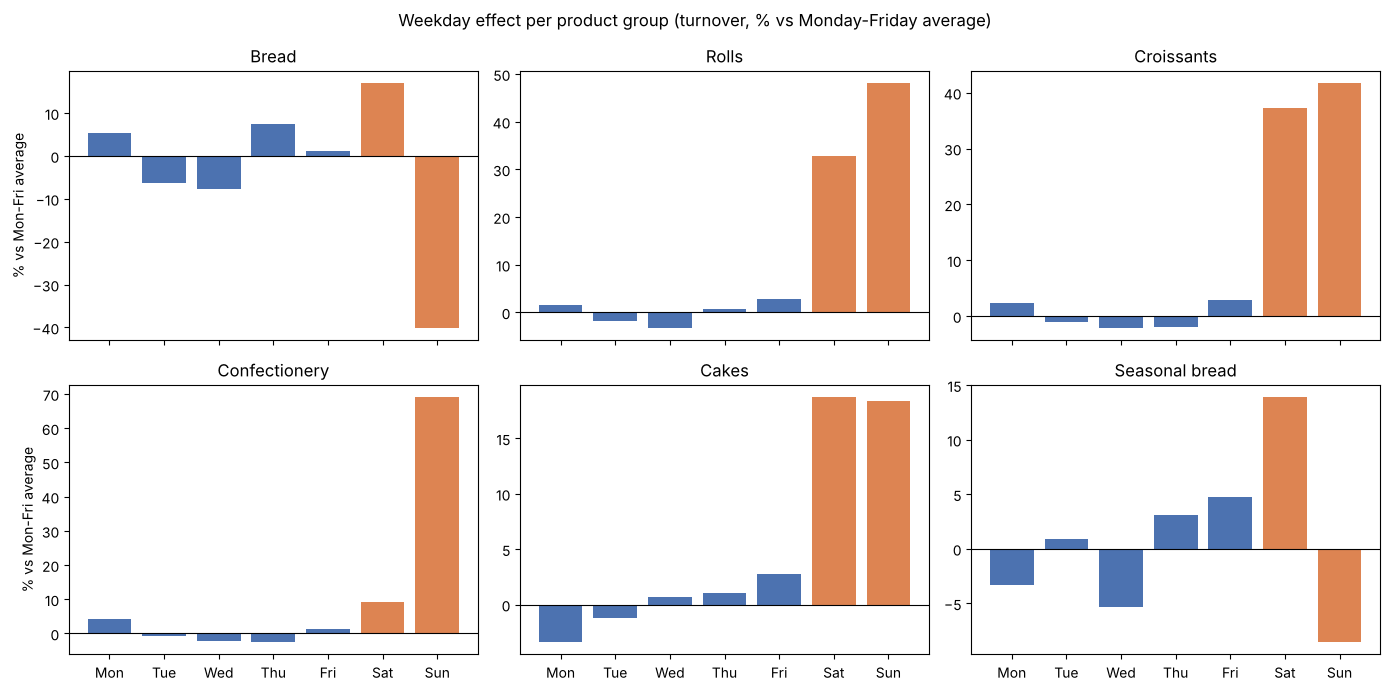

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, g in zip(axes.flat, GROUPS.values()):
    ax.bar(range(7), wd_pct.loc[g, WEEKDAYS], color=["#4c72b0"] * 5 + ["#dd8452"] * 2)
    ax.axhline(0, color="black", lw=0.8); ax.set_title(g)
    ax.set_xticks(range(7), [d[:3] for d in WEEKDAYS])
for ax in axes[:, 0]: ax.set_ylabel("% vs Mon-Fri average")
fig.suptitle("Weekday effect per product group (turnover, % vs Monday-Friday average)")
plt.tight_layout(); plt.show()

## 4. Weather and Kiel Week, controlling for weekday, month and year

We fit one **regression** (OLS) per product group:

`log(turnover) ~ temperature + cloud cover + Kiel Week + weekday + month + year`

- **Controlling** for weekday, month and year means: we compare days that share the same weekday, month and year, so that e.g. "warm" is not just a stand-in for "summer".
- Using **log** turnover lets us read each effect as a **% change**: `(exp(coefficient) - 1) * 100`.
- Days next to each other are similar, which makes ordinary standard errors too optimistic. We use **HAC** (Newey-West, 7 days) standard errors to correct for that.
- Temperature and month are related, so the temperature effect is the extra effect *within* a month.

In [8]:
model_df = df.dropna(subset=["Temperatur", "Bewoelkung"]).copy()
print(f"Rows used: {len(model_df)} of {len(df)} (rows without temperature or cloud cover dropped)")
formula = "np.log(Umsatz) ~ Temperatur + Bewoelkung + KielerWoche + C(weekday) + C(month) + C(year)"
res_rows = []
for code_, g in GROUPS.items():
    d = model_df[model_df.Warengruppe == code_].sort_values("Datum")
    f = formula if d.KielerWoche.sum() > 0 else formula.replace(" + KielerWoche", "")
    m = smf.ols(f, data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    for var, label in [("Temperatur", "per +1 °C"), ("Bewoelkung", "per +1 octa cloud"), ("KielerWoche", "Kiel Week day")]:
        if var not in m.params: 
            res_rows.append({"group": g, "factor": label, "n days": int(m.nobs), "effect %": np.nan, "95% CI low": np.nan, "95% CI high": np.nan, "p": np.nan}); continue
        lo, hi = m.conf_int().loc[var]
        res_rows.append({"group": g, "factor": label, "n days": int(m.nobs),
                         "effect %": (np.exp(m.params[var]) - 1) * 100,
                         "95% CI low": (np.exp(lo) - 1) * 100, "95% CI high": (np.exp(hi) - 1) * 100,
                         "p": m.pvalues[var]})
effects = pd.DataFrame(res_rows)
with pd.option_context("display.float_format", "{:.2f}".format):
    print(effects.to_string(index=False))

Rows used: 9264 of 9334 (rows without temperature or cloud cover dropped)


         group            factor  n days  effect %  95% CI low  95% CI high    p
         Bread         per +1 °C    1807     -0.22       -0.65         0.21 0.32
         Bread per +1 octa cloud    1807     -0.29       -0.74         0.16 0.21
         Bread     Kiel Week day    1807      9.55        2.26        17.36 0.01
         Rolls         per +1 °C    1807      0.56        0.19         0.92 0.00
         Rolls per +1 octa cloud    1807     -0.41       -0.78        -0.03 0.03
         Rolls     Kiel Week day    1807     21.09       16.21        26.18 0.00
    Croissants         per +1 °C    1807      0.48        0.01         0.96 0.05
    Croissants per +1 octa cloud    1807     -0.76       -1.22        -0.30 0.00
    Croissants     Kiel Week day    1807     26.17       19.22        33.52 0.00
 Confectionery         per +1 °C    1754     -0.49       -0.96        -0.02 0.04
 Confectionery per +1 octa cloud    1754     -0.42       -0.97         0.14 0.14
 Confectionery     Kiel Week

Seasonal bread has no Kiel Week rows (Kiel Week is in June), so that effect cannot be estimated for it.

## 5. Holidays: 24-26 Dec, 31 Dec and 1 Jan vs other December/January days

For each product group we compare the average turnover on each holiday date with the average of all **other** December and January days. **n years** shows on how many years (out of 5) the bakery had sales that day; a missing date usually means the shop was closed.

In [9]:
dj = df[df.month.isin([12, 1])].copy()
dj["md"] = dj.Datum.dt.strftime("%d %b")
HOL = ["24 Dec", "25 Dec", "26 Dec", "31 Dec", "01 Jan"]
other = dj[~dj.md.isin(HOL)].groupby("group").Umsatz.mean()
rows = []
for g in GROUPS.values():
    for h in HOL:
        d = dj[(dj.group == g) & (dj.md == h)]
        rows.append({"group": g, "date": h, "n years": len(d),
                     "change vs other Dec/Jan days %": (d.Umsatz.mean() / other[g] - 1) * 100 if len(d) else np.nan})
hol = pd.DataFrame(rows).pivot(index="group", columns="date", values=["n years", "change vs other Dec/Jan days %"]).reindex(list(GROUPS.values()))
print(hol.round(0).to_string())
print("\nYears in data with any sales on each date:", {h: int(dj[dj.md == h].year.nunique()) for h in HOL})

               n years                             change vs other Dec/Jan days %                            
date            01 Jan 24 Dec 25 Dec 26 Dec 31 Dec                         01 Jan 24 Dec 25 Dec 26 Dec 31 Dec
group                                                                                                        
Bread              0.0    5.0    0.0    0.0    5.0                            NaN   99.0    NaN    NaN  120.0
Rolls              0.0    5.0    0.0    0.0    5.0                            NaN   55.0    NaN    NaN   93.0
Croissants         0.0    5.0    0.0    0.0    5.0                            NaN   16.0    NaN    NaN   65.0
Confectionery      0.0    3.0    0.0    0.0    2.0                            NaN   16.0    NaN    NaN  -43.0
Cakes              0.0    5.0    0.0    0.0    5.0                            NaN    4.0    NaN    NaN  627.0
Seasonal bread     0.0    5.0    0.0    0.0    1.0                            NaN  -26.0    NaN    NaN  -45.0

Years in 

## 6. What to take away

The numbers above feed the summary table and the **Week 3** section of `FINDINGS.md`. Remember the limits: turnover (not pieces), observed weather (not forecasts), and only 5 Kiel Weeks and 5 Christmas seasons.